# Vision — Klasifikasi CLIP Zero-shot
**Kapan dipakai:** klasifikasi gambar dengan label sedikit/tidak ada, kelasnya benda umum yang
bisa ditulis dengan kata (kucing, mobil, pesawat).

**Langkah:** tiap kelas diubah jadi kalimat (`TEMPLATE`) → CLIP mengubah gambar dan kalimat
jadi vektor → gambar diberi kelas yang kalimatnya paling mirip. Tidak ada latih.

**Data demo:** CIFAR-10 kecil (gambar 32x32, 10 kelas). Bobot: `pretrained/clip_b32`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import train_test_split
from torch.nn import functional
from transformers import CLIPModel, CLIPProcessor

## Konfigurasi

In [2]:
DATA_FOLDER = "Z:/GEMASTIK-DATABASE/data_latihan/vision/classification/cifar10_small"  # GANTI
TRAIN_CSV = f"{DATA_FOLDER}/train.csv"
TEST_CSV = f"{DATA_FOLDER}/test.csv"
TEST_KEY_CSV = f"{DATA_FOLDER}/test_labels.csv"   # hanya ada di data latihan
CLIP_FOLDER = "Z:/GEMASTIK-DATABASE/pretrained/clip_b32"

PATH_COL = "path"     # path gambar, relatif terhadap DATA_FOLDER
TARGET = "label"
BATCH_SIZE = 64
SEED = 42
TEMPLATE = "a photo of a {}"
# TEMPLATE = "a photo of the small {}"
# TEMPLATE = "a low-resolution photo of a {}"
# TEMPLATE = "a blurry picture of a {}"
DEVICE = "cpu"
if torch.cuda.is_available():
    DEVICE = "cuda"

## Baca data

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
print("train:", train.shape, "| test:", test.shape)
print(train[TARGET].value_counts())
train.head()

train: (4000, 2) | test: (1000, 2)
label
airplane      400
automobile    400
bird          400
cat           400
deer          400
dog           400
frog          400
horse         400
ship          400
truck         400
Name: count, dtype: int64


,path,label
0,train/airplane/0000.png,airplane
1,train/airplane/0001.png,airplane
2,train/airplane/0002.png,airplane
3,train/airplane/0003.png,airplane
4,train/airplane/0004.png,airplane


## Split (zero-shot tidak butuh latih, validasi hanya untuk mengukur)

In [4]:
train_part, val_part = train_test_split(train, test_size=0.2, stratify=train[TARGET],
                                        random_state=SEED)
classes = sorted(train[TARGET].unique())
print("kelas:", classes)

kelas: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## Model CLIP + vektor kalimat tiap kelas

In [5]:
clip = CLIPModel.from_pretrained(CLIP_FOLDER, local_files_only=True)
processor = CLIPProcessor.from_pretrained(CLIP_FOLDER, local_files_only=True)
clip = clip.to(DEVICE)
clip.eval()

prompts = []
for name in classes:
    prompts.append(TEMPLATE.format(name))
print("prompt:", prompts[:3])

with torch.no_grad():
    encoded = processor(text=prompts, return_tensors="pt", padding=True).to(DEVICE)
    text_vectors = clip.get_text_features(**encoded).pooler_output
text_vectors = functional.normalize(text_vectors, dim=-1)
text_vectors = text_vectors.cpu().numpy()

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

prompt: ['a photo of a airplane', 'a photo of a automobile', 'a photo of a bird']


## Vektor gambar + tebak kelas
`predict_classes`: kelas dengan kemiripan (perkalian vektor) tertinggi.

In [6]:
def image_vectors(paths):
    batches = []
    for start in range(0, len(paths), BATCH_SIZE):
        images = []
        for path in paths[start:start + BATCH_SIZE]:
            images.append(Image.open(f"{DATA_FOLDER}/{path}").convert("RGB"))
        encoded = processor(images=images, return_tensors="pt").to(DEVICE)
        with torch.no_grad():
            batches.append(clip.get_image_features(**encoded).pooler_output.cpu())
    vectors = torch.cat(batches)
    return functional.normalize(vectors, dim=-1).numpy()


def predict_classes(paths):
    similarity = image_vectors(paths) @ text_vectors.T
    return np.array(classes)[similarity.argmax(axis=1)]


print(predict_classes(list(val_part[PATH_COL][:5])), list(val_part[TARGET][:5]))

['cat' 'frog' 'truck' 'automobile' 'automobile'] ['deer', 'frog', 'truck', 'automobile', 'automobile']


## Evaluasi di validasi

F1 macro: 0.8586
              precision    recall  f1-score   support

    airplane       0.93      0.88      0.90        80
  automobile       0.80      0.97      0.88        80
        bird       0.83      0.89      0.86        80
         cat       0.78      0.82      0.80        80
        deer       0.92      0.74      0.82        80
         dog       0.81      0.84      0.82        80
        frog       0.97      0.75      0.85        80
       horse       0.78      0.91      0.84        80
        ship       0.87      0.95      0.91        80
       truck       0.99      0.84      0.91        80

    accuracy                           0.86       800
   macro avg       0.87      0.86      0.86       800
weighted avg       0.87      0.86      0.86       800



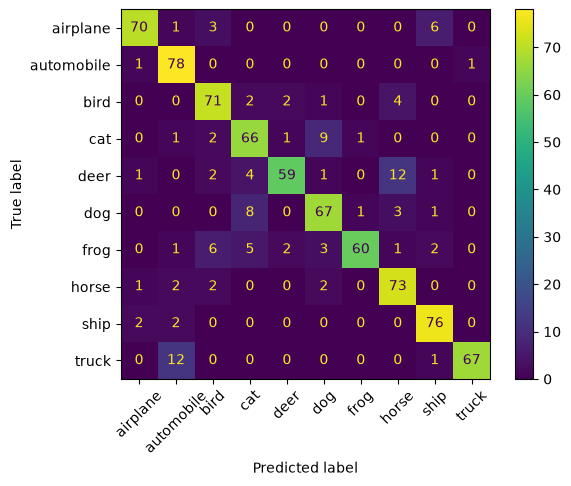

In [7]:
val_predictions = predict_classes(list(val_part[PATH_COL]))
print("F1 macro:", round(f1_score(val_part[TARGET], val_predictions, average="macro"), 4))
print(classification_report(val_part[TARGET], val_predictions))
ConfusionMatrixDisplay.from_predictions(val_part[TARGET], val_predictions, xticks_rotation=45)
plt.show()

## Prediksi test + submission (tanpa latih ulang)

In [8]:
predictions = predict_classes(list(test[PATH_COL]))

submission = pd.DataFrame()
submission["id"] = test["id"]
submission["label"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,id,label
0,1,airplane
1,2,airplane
2,3,airplane
3,4,airplane
4,5,airplane


## Cek dengan kunci jawaban latihan
**HAPUS sel ini saat lomba**: file kunci hanya ada di data latihan.

In [9]:
test_key = pd.read_csv(TEST_KEY_CSV)["label"]
print("F1 macro test (kunci latihan):", round(f1_score(test_key, predictions, average="macro"), 4))

F1 macro test (kunci latihan): 0.8805
